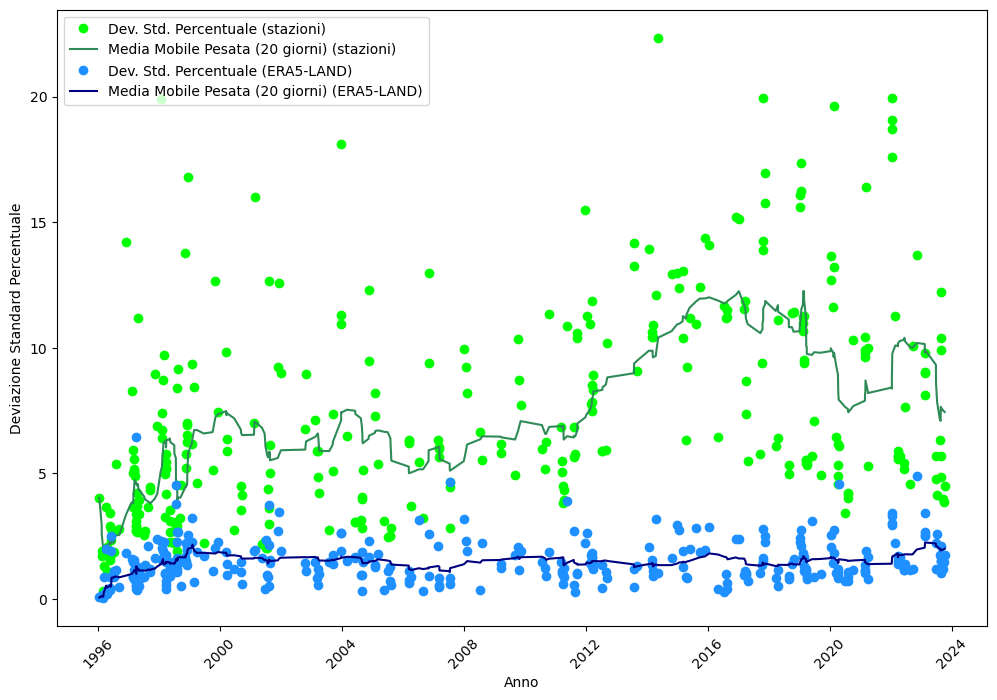

La media pesata totale della deviazione standard percentuale (rad) è: 8.14%
La media pesata totale della deviazione standard percentuale (shortwave_radiation) è: 1.56%


In [4]:
import matplotlib.dates as mdates
import pandas as pd
import matplotlib.pyplot as plt

# Funzione per calcolare la media, la deviazione standard percentuale e il numero di stazioni per ogni giorno
def calcola_media_devstd_percentuale(df, colonna):
    # Raggruppa i dati per 'data', calcola la media, la deviazione standard e il numero di dati
    risultati = df.groupby('data')[colonna].agg(['mean', 'std', 'count']).reset_index()

    # Calcola la deviazione standard percentuale rispetto alla media
    risultati['dev_std_percentuale'] = (risultati['std'] / risultati['mean']) * 100

    # Rimuove eventuali valori nulli generati da calcoli su una singola stazione
    risultati = risultati.dropna()

    # Rinomina la colonna 'count' come 'num_stazioni' per chiarezza
    risultati.rename(columns={'count': 'num_stazioni'}, inplace=True)

    return risultati

# Carica il file CSV aggregato
df = pd.read_csv(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\ARPA\ERA_PV_stazioni_clearsky_giornalieri.csv')  # Inserisci il percorso corretto del file

# Esegui il calcolo di media, deviazione standard percentuale e numero di stazioni per entrambe le colonne
risultati_rad = calcola_media_devstd_percentuale(df, 'rad')
risultati_shortwave = calcola_media_devstd_percentuale(df, 'shortwave_radiation')

# Verifica e conversione sicura della colonna 'data' in formato datetime per entrambi i set di dati
risultati_rad['data'] = pd.to_datetime(risultati_rad['data'], errors='coerce')
risultati_shortwave['data'] = pd.to_datetime(risultati_shortwave['data'], errors='coerce')

# Verifica che non ci siano valori nulli dopo la conversione
risultati_rad = risultati_rad.dropna(subset=['data'])
risultati_shortwave = risultati_shortwave.dropna(subset=['data'])

# Funzione per calcolare la media mobile pesata
def calcola_media_mobile_pesata(risultati):
    # Calcolo del numeratore della media mobile pesata (dev_std_percentuale * num_stazioni)
    risultati['numeratore_pesato'] = risultati['dev_std_percentuale'] * risultati['num_stazioni']

    # Calcolo della somma ponderata su una finestra di 20 giorni (somma pesata)
    somma_pesata = risultati['numeratore_pesato'].rolling(window=20, min_periods=1).sum()

    # Calcolo della somma dei pesi (num_stazioni) su una finestra di 20 giorni
    somma_pesi = risultati['num_stazioni'].rolling(window=20, min_periods=1).sum()

    # Calcolo della media mobile pesata
    risultati['media_mobile_pesata'] = somma_pesata / somma_pesi

# Calcolo della media mobile pesata per entrambi i set di dati
calcola_media_mobile_pesata(risultati_rad)
calcola_media_mobile_pesata(risultati_shortwave)

# Crea il grafico
plt.figure(figsize=(12, 8))

# Grafico della deviazione standard percentuale per 'rad'
plt.plot(risultati_rad['data'], risultati_rad['dev_std_percentuale'],
         marker='o', color='#00ff00', linestyle='None', label='Dev. Std. Percentuale (stazioni)')

# Grafico della media mobile pesata per 'rad'
plt.plot(risultati_rad['data'], risultati_rad['media_mobile_pesata'],
         color='#2e8b57', linestyle='-', label='Media Mobile Pesata (20 giorni) (stazioni)')

# Grafico della deviazione standard percentuale per 'shortwave_radiation'
plt.plot(risultati_shortwave['data'], risultati_shortwave['dev_std_percentuale'],
         marker='o', color='#1e90ff', linestyle='None', label='Dev. Std. Percentuale (ERA5-LAND)')

# Grafico della media mobile pesata per 'shortwave_radiation'
plt.plot(risultati_shortwave['data'], risultati_shortwave['media_mobile_pesata'],
         color='#000080', linestyle='-', label='Media Mobile Pesata (20 giorni) (ERA5-LAND)')

# Imposta il formato delle etichette dell'asse X per mostrare solo gli anni ogni 4 anni
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(4))  # Mostra una tacca ogni 4 anni
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # Mostra solo l'anno come etichetta

# Aggiungi etichette e titolo
plt.xlabel('Anno')
plt.ylabel('Deviazione Standard Percentuale')

# Ruota le etichette sull'asse X per leggibilità
plt.xticks(rotation=45)

# Mostra la leggenda
plt.legend()

# Salva il grafico
plt.savefig('deviazione_std_percentuale_con_media_mobile_pesata_confronto.png', bbox_inches='tight')

# Mostra il grafico
plt.show()

# Calcolo della media pesata totale per 'rad'
somma_totale_pesata_rad = (risultati_rad['dev_std_percentuale'] * risultati_rad['num_stazioni']).sum()
somma_totale_stazioni_rad = risultati_rad['num_stazioni'].sum()
media_pesata_totale_rad = somma_totale_pesata_rad / somma_totale_stazioni_rad

# Calcolo della media pesata totale per 'shortwave_radiation'
somma_totale_pesata_shortwave = (risultati_shortwave['dev_std_percentuale'] * risultati_shortwave['num_stazioni']).sum()
somma_totale_stazioni_shortwave = risultati_shortwave['num_stazioni'].sum()
media_pesata_totale_shortwave = somma_totale_pesata_shortwave / somma_totale_stazioni_shortwave

# Stampa le medie pesate totali
print(f"La media pesata totale della deviazione standard percentuale (rad) è: {media_pesata_totale_rad:.2f}%")
print(f"La media pesata totale della deviazione standard percentuale (shortwave_radiation) è: {media_pesata_totale_shortwave:.2f}%")
